In [68]:
import pandas as pd

# Load CSV
data = pd.read_csv("../data/Indoor Air Pollution Data.csv", low_memory=False)
data.describe()

,NH3,CO,PM2.5,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
count,173465.000000,173465.000000,173465.000000,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.00
mean,0.670185,4.339625,0.057456,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
std,0.177971,1.615590,0.116102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.290000,0.290000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
25%,0.540000,3.610000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
50%,0.650000,4.190000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
75%,0.750000,4.860000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
max,1.630000,9.920000,0.470000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45


In [69]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173468 entries, 0 to 173467
Data columns (total 19 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   NH3          173465 non-null  float64
 1   NO2          173468 non-null  object 
 2   CO           173465 non-null  float64
 3   PM2.5        173465 non-null  float64
 4   Temp         173465 non-null  object 
 5   Pressure     173465 non-null  object 
 6   Humidity     173465 non-null  object 
 7   O3           173465 non-null  object 
 8   Date         173465 non-null  object 
 9   Unnamed: 9   1 non-null       float64
 10  Unnamed: 10  1 non-null       float64
 11  Unnamed: 11  1 non-null       float64
 12  Unnamed: 12  1 non-null       float64
 13  Unnamed: 13  1 non-null       float64
 14  Unnamed: 14  1 non-null       float64
 15  Unnamed: 15  1 non-null       float64
 16  Unnamed: 16  1 non-null       float64
 17  Unnamed: 17  1 non-null       float64
 18  Unnamed: 18  1 non-null 

In [70]:
# Drop unnamed columns
data.drop(columns=[col for col in data.columns if "Unnamed" in col], inplace=True)

In [71]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3         3
CO          3
PM2.5       3
Temp        3
Pressure    3
Humidity    3
O3          3
Date        3
dtype: int64


In [59]:
data['Temp'] = pd.to_numeric(data['Temp'], errors='coerce')
data['Pressure'] = pd.to_numeric(data['Pressure'], errors='coerce')
data['Humidity'] = pd.to_numeric(data['Humidity'], errors='coerce')


In [60]:
print("Temperature:")
print(data['Temp'].describe())

print("\nPressure:")
print(data['Pressure'].describe())

print("\nHumidity:")
print(data['Humidity'].describe())


Temperature:
count    169939.000000
mean         29.425533
std           2.543658
min        -140.460000
25%          28.170000
50%          29.100000
75%          30.620000
max          35.480000
Name: Temp, dtype: float64

Pressure:
count    169940.000000
mean        941.257246
std           4.425494
min         929.750000
25%         939.380000
50%         942.020000
75%         943.870000
max        1202.850000
Name: Pressure, dtype: float64

Humidity:
count    169934.000000
mean         46.559450
std          16.970196
min           0.000000
25%          33.370000
50%          43.500000
75%          56.857500
max         100.000000
Name: Humidity, dtype: float64


In [61]:
data = data[
    (data['Temp'] > -40) &        # BME280 lower bound
    (data['Pressure'] < 1100) &   # discard unrealistic pressure
    (data['Humidity'] < 100)      # discard 100% which is consistently an error here
]


In [62]:
data['Temp'] = data['Temp'].fillna(data['Temp'].mean())
data['Pressure'] = data['Pressure'].fillna(data['Pressure'].mean())
data['Humidity'] = data['Humidity'].fillna(data['Humidity'].mean())


In [72]:
data.dropna(inplace=True)

In [73]:
for col in data.columns[:-1]:  # skip last column (e.g., 'Date')
    # Identify values with non-digit/non-dot characters or more than one dot
    mask = data[col].astype(str).str.contains(r'[^0-9.]') | (data[col].astype(str).str.count(r'\.') > 1)
    bad_values = data.loc[mask, col]

    if not bad_values.empty:
        print(f"\n❌ Suspicious values in column '{col}':")
        print(bad_values.unique())



❌ Suspicious values in column 'Temp':
['-140.46' ' NAN']

❌ Suspicious values in column 'Pressure':
[' NAN']

❌ Suspicious values in column 'Humidity':
[' NAN']

❌ Suspicious values in column 'O3':
['12.450.73']


In [74]:
data = data.replace(' NAN', pd.NA)


In [75]:
data = data.dropna()


In [76]:
data['Temp'] = pd.to_numeric(data['Temp'], errors='coerce')
data.loc[data['Temp'] < -50, 'Temp'] = pd.NA


In [77]:
def fix_dot_keep_first(val):
    if pd.isna(val): return val
    val = str(val)
    if val.count('.') > 1:
        parts = val.split('.')
        return parts[0] + '.' + ''.join(parts[1:])  # keep first dot
    return val


data['O3'] = data['O3'].apply(fix_dot_keep_first)
data['O3'] = pd.to_numeric(data['O3'], errors='coerce')


In [ ]:
# data.dropna(inplace=True)
# # Remove duplicate rows if any
# data = data.drop_duplicates()
# # Fix numeric columns with bad characters (like '12.450.73')
# for col in data.columns[:-1]:  # skip 'Date' column
#     data[col] = data[col].astype(str).str.replace('[^0-9.]', '', regex=True)
#     data[col] = data[col].apply(lambda x: x if x.count('.') <= 1 else x.replace('.', '', x.count('.') - 1))  # keep last dot
#     data[col] = pd.to_numeric(data[col], errors='coerce')

In [78]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Temp    15
dtype: int64


In [79]:
data = data.dropna()


In [80]:
data = data.set_index('Date')

In [ ]:
# # Step 1: Manually create 10 seed "Good" records
# good_sample = {
#     'PM2.5': 25.0,
#     'CO_mgm3': 2.5,
#     'NO2_ugm3': 50.0,
#     'NH3_ugm3': 25.0,       # optional: include if needed
#     'O3_ugm3': 45.0,
#     'Temp': 25.0,
#     'Humidity': 50.0,
#     'Pressure': 1013.25,
#     'EAQI_Category': 'Good'
# }

# synthetic_good_df = pd.DataFrame([good_sample] * 10)

# # Add a flag for tracking
# synthetic_good_df['is_synthetic'] = True
# data['is_synthetic'] = False

# # Step 2: Combine original and synthetic "Good" records
# data = pd.concat([data, synthetic_good_df], ignore_index=True)

In [81]:


# Constants
R = 8.3145  # m³·Pa/(mol·K)
MW = {
    'CO': 28.01,    # Carbon Monoxide (ppm)
    'NO2': 46.01,   # Nitrogen Dioxide (ppm)
    'NH3': 17.03,   # Ammonia (ppm)
    'O3': 48.00     # Ozone (ppb)
}

# --- Conversion Functions (consistent with SI units) ---

def ppm_to_mg_m3(ppm, mw, temp_c, pressure_hpa):
    T = temp_c + 273.15
    P = pressure_hpa * 100  # hPa → Pa
    return (ppm * mw * P) / (R * T * 1e3)  # Divide by 1000 to get mg/m³


def ppm_to_ug_m3(ppm, mw, temp_c, pressure_hpa):
    T = temp_c + 273.15
    P = pressure_hpa * 100
    return (ppm * mw * P * 1e3) / (R * T * 1e3)  # Additional 1e3 cancel → correct scale


def ppb_to_ug_m3(ppb, mw, temp_c, pressure_hpa):
    T = temp_c + 273.15
    P = pressure_hpa * 100
    return (ppb * mw * P) / (R * T * 1e3)  # Divide by 1000 to scale to µg/m³




# --- Ensure columns are numeric ---
for col in ['CO', 'NO2', 'NH3', 'O3', 'Temp', 'Pressure', 'PM2.5']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# --- Apply Conversions ---
data['CO_mgm3'] = data.apply(lambda row: ppm_to_mg_m3(row['CO'], MW['CO'], row['Temp'], row['Pressure']), axis=1)
data['NO2_ugm3'] = data.apply(lambda row: ppm_to_ug_m3(row['NO2'], MW['NO2'], row['Temp'], row['Pressure']), axis=1)
data['NH3_ugm3'] = data.apply(lambda row: ppm_to_ug_m3(row['NH3'], MW['NH3'], row['Temp'], row['Pressure']), axis=1)
data['O3_ugm3'] = data.apply(lambda row: ppb_to_ug_m3(row['O3'], MW['O3'], row['Temp'], row['Pressure']), axis=1)

data['O3_ugm3'] = data['O3_ugm3'].clip(upper=3853.0)
# --- EAQI Breakpoints ---
eaqi_breakpoints = {
    'PM2.5': [
        (0.0, 50.4, 0, 50),
        (50.5, 60.4, 51, 100),
        (60.5, 75.4, 101, 150),
        (75.5, 150.4, 151, 200),
        (150.5, 250.4, 201, 300),
        (250.5, 500.4, 301, 500)
    ],
    'CO_mgm3': [
    (0.0, 5.4, 0, 50),
    (5.4, 10.4, 51, 100),
    (10.4, 14.4, 101, 150),
    (14.4, 17.9, 151, 200),
    (17.9, 35.4, 201, 300),
    (35.4, 58.4, 301, 500)
    ],
    'NO2_ugm3': [
    (0.0, 100.0, 0, 50),
    (100.0, 400.0, 51, 100),
    (400.0, 677.0, 101, 150),
    (677.0, 1221.0, 151, 200),
    (1221.0, 2349.0, 201, 300),
    (2349.0, 3853.0, 301, 500)
],
    'O3_ugm3': [
    (0.0, 100.0, 0, 50),
    (100.0, 400.0, 51, 100),
    (400.0, 677.0, 101, 150),
    (677.0, 1221.0, 151, 200),
    (1221.0, 2349.0, 201, 300),
    (2349.0, 3853.0, 301, 500)
]

}

# --- EAQI Sub-Index Calculation ---
def calculate_eaqi_sub_index(value, breakpoints):
    if pd.isna(value):
        return None
    for BPLo, BPHi, ILo, IHi in breakpoints:
        if value >= BPLo and value <= BPHi:  # inclusive lower and upper bounds
            return round(((IHi - ILo) / (BPHi - BPLo)) * (value - BPLo) + ILo)
    if value < breakpoints[0][0]:
        return breakpoints[0][2]  # minimum EAQI
    elif value > breakpoints[-1][1]:
        return breakpoints[-1][3]  # maximum EAQI
    return None

  

# --- Apply Sub-Index Calculation ---
data['EAQI_PM25'] = data['PM2.5'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['PM2.5']))
data['EAQI_CO'] = data['CO_mgm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['CO_mgm3']))
data['EAQI_NO2'] = data['NO2_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['NO2_ugm3']))
data['EAQI_O3'] = data['O3_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['O3_ugm3']))

# --- Final EAQI Score (Maximum of sub-indices) ---
data['EAQI_Overall'] = data[['EAQI_PM25', 'EAQI_CO', 'EAQI_NO2', 'EAQI_O3']].max(axis=1)

# --- Classify Overall EAQI Category ---
def classify_eaqi(index_value):
    if pd.isna(index_value):
        return None
    elif index_value <= 50:
        return "Good"
    elif index_value <= 100:
        return "Moderate"
    elif index_value <= 150:
        return "Unhealthy for sensitive groups"
    elif index_value <= 200:
        return "Unhealthy"
    elif index_value <= 300:
        return "Very unhealthy"
    elif index_value <= 500:
        return "Hazardous"
    else:
        return "Out of Range"

data['EAQI_Category'] = data['EAQI_Overall'].apply(classify_eaqi)


In [82]:
print(data[['CO_mgm3', 'NO2_ugm3', 'O3_ugm3']].isna().sum())


CO_mgm3     0
NO2_ugm3    0
O3_ugm3     0
dtype: int64


In [42]:
print(data.loc[data['EAQI_CO'].isna(), 'CO_mgm3'].value_counts().head(10))


CO_mgm3
2.5    10
Name: count, dtype: int64


In [43]:
print(data.loc[data['EAQI_NO2'].isna(), 'NO2_ugm3'].value_counts().head(10))
print(data.loc[data['EAQI_O3'].isna(), 'O3_ugm3'].value_counts().head(10))


NO2_ugm3
50.0    10
Name: count, dtype: int64
O3_ugm3
45.0    10
Name: count, dtype: int64


In [83]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Series([], dtype: int64)


In [295]:
# Look at some rows where EAQI_CO is missing
print(data.loc[data['EAQI_CO'].isna(), 'CO_mgm3'].describe())


count    1514.000000
mean        5.453300
std         0.131240
min         5.400128
25%         5.422624
50%         5.449634
75%         5.476961
max        10.428679
Name: CO_mgm3, dtype: float64


In [246]:
print("Rows where EAQI_CO is NaN:")
print(data.loc[data['EAQI_CO'].isna(), ['CO', 'Temp', 'Pressure']].isna().sum())

print("\nRows where EAQI_NO2 is NaN:")
print(data.loc[data['EAQI_NO2'].isna(), ['NO2', 'Temp', 'Pressure']].isna().sum())

print("\nRows where EAQI_O3 is NaN:")
print(data.loc[data['EAQI_O3'].isna(), ['O3', 'Temp', 'Pressure']].isna().sum())


Rows where EAQI_CO is NaN:
CO          0
Temp        0
Pressure    0
dtype: int64

Rows where EAQI_NO2 is NaN:
NO2         0
Temp        0
Pressure    0
dtype: int64

Rows where EAQI_O3 is NaN:
O3          0
Temp        0
Pressure    0
dtype: int64


In [245]:
print(data[['CO_mgm3', 'NO2_ugm3', 'O3_ugm3']].describe())
print(data[['EAQI_CO', 'EAQI_NO2', 'EAQI_O3']].isna().sum())


             CO_mgm3       NO2_ugm3        O3_ugm3
count  169918.000000  169918.000000  169918.000000
mean        4.554177     269.469128      27.384136
std         1.700377     132.364962     100.842093
min         0.307267     103.416335       2.388190
25%         3.805134     189.869275      10.924509
50%         4.397857     241.184688      16.960059
75%         5.087075     289.538462      23.925750
max        10.428679    2478.222781    3853.000000
EAQI_CO     1514
EAQI_NO2      53
EAQI_O3       41
dtype: int64


In [194]:
print(data[['CO_mgm3', 'NO2_ugm3', 'O3_ugm3']].isna().sum())


CO_mgm3     0
NO2_ugm3    0
O3_ugm3     0
dtype: int64


In [45]:
co_min, co_max = eaqi_breakpoints['CO_mgm3'][0][0], eaqi_breakpoints['CO_mgm3'][-1][1]
bad_co = data[~data['CO_mgm3'].between(co_min, co_max)]
print(f"Out-of-range CO values:\n{bad_co['CO_mgm3'].value_counts().head(10)}")

no2_min, no2_max = eaqi_breakpoints['NO2_ugm3'][0][0], eaqi_breakpoints['NO2_ugm3'][-1][1]
bad_no2 = data[~data['NO2_ugm3'].between(no2_min, no2_max)]
print(f"Out-of-range NO2 values:\n{bad_no2['NO2_ugm3'].value_counts().head(10)}")

o3_min, o3_max = eaqi_breakpoints['O3_ugm3'][0][0], eaqi_breakpoints['O3_ugm3'][-1][1]
bad_o3 = data[~data['O3_ugm3'].between(o3_min, o3_max)]
print(f"Out-of-range O3 values:\n{bad_o3['O3_ugm3'].value_counts()}")


Out-of-range CO values:
Series([], Name: count, dtype: int64)
Out-of-range NO2 values:
Series([], Name: count, dtype: int64)
Out-of-range O3 values:
Series([], Name: count, dtype: int64)


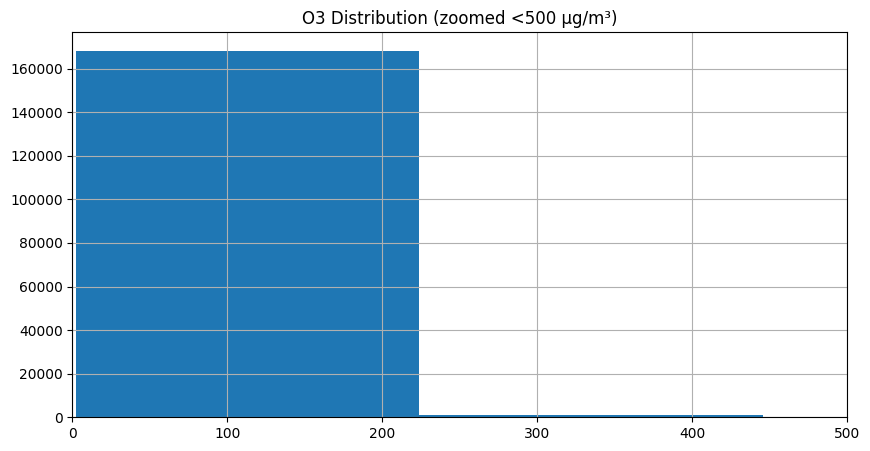

In [163]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
data['O3_ugm3'].hist(bins=100)
plt.xlim(0, 500)  # Zoom into reasonable range
plt.title('O3 Distribution (zoomed <500 µg/m³)')
plt.show()


In [162]:
print(data[['O3_ugm3']].describe())


             O3_ugm3
count  169918.000000
mean       28.591859
std       178.976775
min         2.388415
25%        10.925539
50%        16.961658
75%        23.928005
max     22150.320849


In [305]:
print((data['EAQI_PM25'] <= 50).sum())
print((data['EAQI_CO'] <= 50).sum())
print((data['EAQI_NO2'] <= 50).sum())
print((data['EAQI_O3'] <= 50).sum())


169918
136790
0
166364


In [306]:
print(((data['EAQI_PM25'] <= 50) &
       (data['EAQI_CO'] <= 50) &
       (data['EAQI_NO2'] <= 50) &
       (data['EAQI_O3'] <= 50)).sum())


0


In [103]:
data = data.dropna()

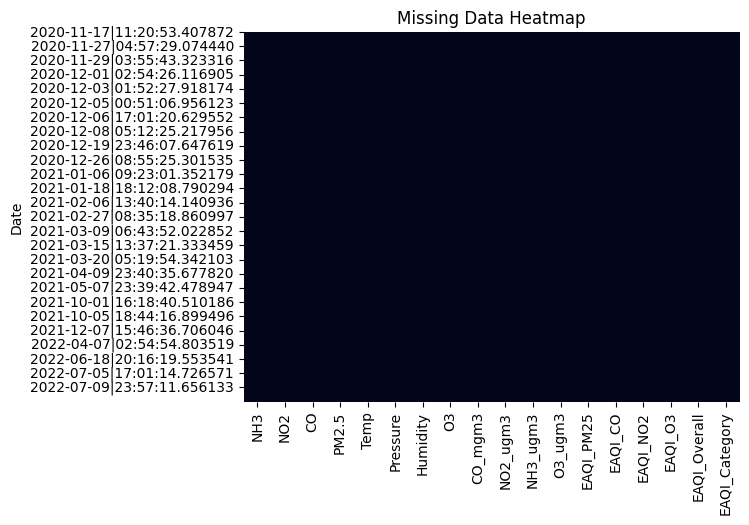

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data.isnull(), cbar=False)
plt.title("Missing Data Heatmap")
plt.show()


In [47]:
print(data['EAQI_Category'].value_counts())


EAQI_Category
Moderate                          151135
Unhealthy for sensitive groups     15760
Unhealthy                           2793
Very unhealthy                       141
Hazardous                             89
Good                                  20
Name: count, dtype: int64


In [84]:
# Count each EAQI category
category_counts = data['EAQI_Category'].value_counts().sort_index()

# Format as a table
print("\n📊 EAQI Category Distribution (based on max pollutant per record):\n")
print("| EAQI Category                     | Count     |")
print("|----------------------------------|-----------|")
for category, count in category_counts.items():
    print(f"| {category:<32} | {count:<9} |")


📊 EAQI Category Distribution (based on max pollutant per record):

| EAQI Category                     | Count     |
|----------------------------------|-----------|
| Hazardous                        | 89        |
| Moderate                         | 151135    |
| Unhealthy                        | 2793      |
| Unhealthy for sensitive groups   | 15760     |
| Very unhealthy                   | 141       |


In [49]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3             20
NO2             20
CO              20
O3              20
EAQI_PM25       20
EAQI_CO         20
EAQI_NO2        20
EAQI_O3         20
EAQI_Overall    20
dtype: int64


In [50]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

  # Replace with your actual file path

# 2. Identify features and target
features = ['PM2.5', 'CO_mgm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
target = 'EAQI_Category'

# 3. Drop columns not needed for training (like EAQI_CO, EAQI_NO2, EAQI_O3)
drop_cols = ['EAQI_CO', 'EAQI_NO2', 'EAQI_O3']
data.drop(columns=[col for col in drop_cols if col in data.columns], inplace=True)

# 4. Check missing values
print("Missing value count:\n", data[features + [target]].isnull().sum())

# 5. Drop rows where target is missing (classification label must be known)
data = data.dropna(subset=[target])

# 6. Impute missing feature values with mean
imputer = SimpleImputer(strategy='mean')
data[features] = imputer.fit_transform(data[features])



# 8. Check if it worked
print("\n✅ Final check: No missing values?\n", data.isnull().sum().sum() == 0)
print("🟢 Class distribution after cleaning:\n", data[target].value_counts())


Missing value count:
 PM2.5            0
CO_mgm3          0
NO2_ugm3         0
NH3_ugm3         0
O3_ugm3          0
Temp             0
Humidity         0
Pressure         0
EAQI_Category    0
dtype: int64

✅ Final check: No missing values?
 False
🟢 Class distribution after cleaning:
 EAQI_Category
Moderate                          151135
Unhealthy for sensitive groups     15760
Unhealthy                           2793
Very unhealthy                       141
Hazardous                             89
Good                                  20
Name: count, dtype: int64


In [35]:
# iaq_model_training_balanced.py

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 1. Load your data


# 2. Subsample 'Moderate' class to 10,000 rows
balanced_data = (
    pd.concat([
        data[data['EAQI_Category'] == 'Moderate'].sample(n=10000, random_state=42),
        data[data['EAQI_Category'] != 'Moderate']
    ])
    .sample(frac=1, random_state=42)  # Shuffle the rows
)

# 3. Prepare features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = balanced_data[features]
y = balanced_data['EAQI_Category']

# 4. Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 5. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 6. Build pipeline: SMOTE + Scaling + Classifier
pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# 7. Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 8. Train final model
pipeline.fit(X_train, y_train)

# 9. Evaluate
y_pred = pipeline.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 10. Save model and encoder
joblib.dump(pipeline, "best_model_pipeline02.pkl")
joblib.dump(le, "label_encoder02.pkl")


CV Macro F1: 0.9941 ± 0.0076

Classification Report:

                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00       712
                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00      2000
                     Unhealthy       1.00      1.00      1.00       559
Unhealthy for sensitive groups       1.00      1.00      1.00      3144
                Very unhealthy       0.97      1.00      0.98        28

                      accuracy                           1.00      6452
                     macro avg       0.99      0.98      0.99      6452
                  weighted avg       1.00      1.00      1.00      6452



['label_encoder02.pkl']

In [38]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Load data

data.dropna(subset=['EAQI_Category'], inplace=True)
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
data.dropna(subset=features, inplace=True)

X = data[features]
y = data['EAQI_Category']

# Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

# Updated: Apply scaler before SMOTE
pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# Final training
pipeline.fit(X_train, y_train)

# Evaluate
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Save
joblib.dump(pipeline, 'best_model_pipeline04.pkl')
joblib.dump(le, 'label_encoder04.pkl')


CV Macro F1: 0.9984 ± 0.0029
                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00       712
                     Hazardous       0.82      1.00      0.90         9
                      Moderate       1.00      1.00      1.00     30242
                     Unhealthy       1.00      1.00      1.00       558
Unhealthy for sensitive groups       1.00      1.00      1.00      3144
                Very unhealthy       1.00      0.96      0.98        28

                      accuracy                           1.00     34693
                     macro avg       0.97      0.99      0.98     34693
                  weighted avg       1.00      1.00      1.00     34693



['label_encoder04.pkl']


 Training & Evaluating: Logistic Regression
 Saved model: trained_models/Logistic_Regression.pkl

 Training & Evaluating: Ridge Classifier
 Saved model: trained_models/Ridge_Classifier.pkl

 Training & Evaluating: Linear SVM
 Saved model: trained_models/Linear_SVM.pkl

 Training & Evaluating: Random Forest
 Saved model: trained_models/Random_Forest.pkl

 Training & Evaluating: Gradient Boosting
 Saved model: trained_models/Gradient_Boosting.pkl

 Training & Evaluating: XGBoost
 Saved model: trained_models/XGBoost.pkl

 Training & Evaluating: KNN
 Saved model: trained_models/KNN.pkl

 Training & Evaluating: Nearest Centroid
 Saved model: trained_models/Nearest_Centroid.pkl

 Training & Evaluating: MLP Classifier
 Saved model: trained_models/MLP_Classifier.pkl

 Training & Evaluating: Naive Bayes
 Saved model: trained_models/Naive_Bayes.pkl

 Training & Evaluating: LightGBM
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006348 seconds.
You can se

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009591 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580356, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013491 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580356, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007389 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580362, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007521 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580362, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009164 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 725448, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
 Saved model: trained_models/LightGBM.pkl

 Training & Evaluating: CatBoost
 Saved model: trained_models/CatBoost.pkl

 Model Performance Summary:
                     CV Ma

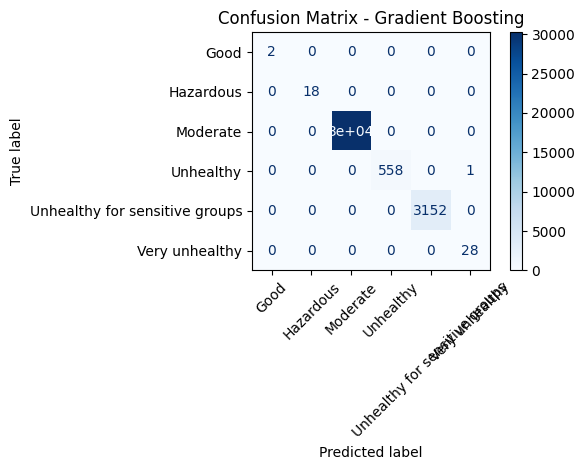

['label_encoder.pkl']

In [355]:
# 1. Import Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

# Optional: LightGBM and CatBoost
has_lightgbm = has_catboost = True
try:
    from lightgbm import LGBMClassifier
except ImportError:
    print(" LightGBM not installed.")
    has_lightgbm = False
try:
    from catboost import CatBoostClassifier
except ImportError:
    print(" CatBoost not installed.")
    has_catboost = False

# 2. Load and Prepare Data (Assumes you already have `data`)
features = ['PM2.5', 'CO_mgm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Define Classifiers
model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(max_iter=10000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300),
    "Naive Bayes": GaussianNB()
}

if has_lightgbm:
    model_defs["LightGBM"] = LGBMClassifier(class_weight='balanced', random_state=42)
if has_catboost:
    model_defs["CatBoost"] = CatBoostClassifier(verbose=0, random_state=42)

# 6. Create Pipelines
models = {}
for name, clf in model_defs.items():
    steps = [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('clf', clf)]
    models[name] = ImbPipeline(steps)

# 7. Train, Evaluate, and Save All Models
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
os.makedirs("trained_models", exist_ok=True)

for name, pipe in models.items():
    print(f"\n Training & Evaluating: {name}")
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    results[name] = {
        "CV Macro F1 (mean)": round(np.mean(f1_scores), 4),
        "CV Macro F1 (std)": round(np.std(f1_scores), 4)
    }
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, f"trained_models/{name.replace(' ', '_')}.pkl")
    print(f" Saved model: trained_models/{name.replace(' ', '_')}.pkl")

# 8. Show Summary Table
results_df = pd.DataFrame(results).T.sort_values(by="CV Macro F1 (mean)", ascending=False)
print("\n Model Performance Summary:")
print(results_df)

# 9. Final Evaluation on Best Model
best_model_name = results_df.index[0]
print(f"\n Final Evaluation on Best Model: {best_model_name}")
best_model = models[best_model_name]
y_pred = best_model.predict(X_test)

print("\n Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Extra metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
mae = mean_absolute_error(y_test, y_pred)

print(f"\n Accuracy: {acc:.4f}")
print(f" Precision (macro): {prec:.4f}")
print(f" Recall (macro): {rec:.4f}")
print(f" F1-score (macro): {f1:.4f}")
print(f" MAE: {mae:.4f}")

# 10. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, xticks_rotation=45, cmap='Blues'
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# 11. Save Best Model and Label Encoder
joblib.dump(best_model, "best_model_pipeline.pkl")
joblib.dump(le, "label_encoder.pkl")



🧪 Training & Evaluating: Logistic Regression
✅ Saved model: trained_models/Logistic_Regression.pkl

🧪 Training & Evaluating: Ridge Classifier
✅ Saved model: trained_models/Ridge_Classifier.pkl

🧪 Training & Evaluating: Linear SVM
✅ Saved model: trained_models/Linear_SVM.pkl

🧪 Training & Evaluating: Random Forest
✅ Saved model: trained_models/Random_Forest.pkl

🧪 Training & Evaluating: Gradient Boosting
✅ Saved model: trained_models/Gradient_Boosting.pkl

🧪 Training & Evaluating: XGBoost
✅ Saved model: trained_models/XGBoost.pkl

🧪 Training & Evaluating: KNN
✅ Saved model: trained_models/KNN.pkl

🧪 Training & Evaluating: Nearest Centroid
✅ Saved model: trained_models/Nearest_Centroid.pkl

🧪 Training & Evaluating: MLP Classifier
✅ Saved model: trained_models/MLP_Classifier.pkl

🧪 Training & Evaluating: Naive Bayes
✅ Saved model: trained_models/Naive_Bayes.pkl

🧪 Training & Evaluating: LightGBM
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.00432

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003406 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 483630, number of used features: 8
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003253 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 483630, number of used features: 8
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003176 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 483635, number of used features: 8
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003338 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 483635, number of used features: 8
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004009 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 604540, number of used features: 8
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
✅ Saved model: trained_models/LightGBM.pkl

🧪 Training & Evaluating: CatBoost
✅ Saved model: trained_models/CatBoost.pkl

📊 Model Performance Summary (Sorted by Accuracy):
                     Accuracy (mean)  Accuracy (std)  F1 Macro (mean)  \
Random Forest                 0.9999          0.0000     

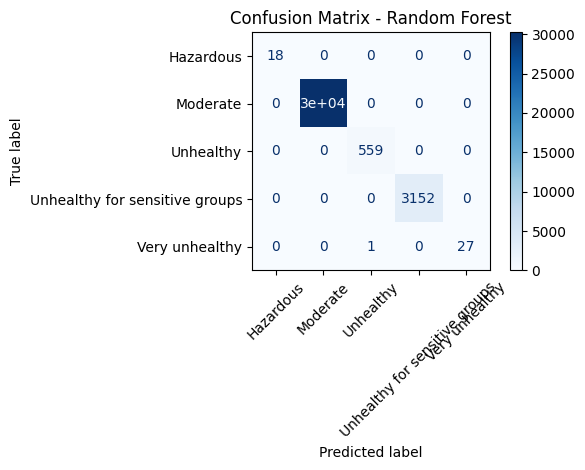

['label_encoder.pkl']

In [ ]:
# 1. Import Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

# Optional: LightGBM and CatBoost
has_lightgbm = has_catboost = True
try:
    from lightgbm import LGBMClassifier
except ImportError:
    print(" LightGBM not installed.")
    has_lightgbm = False
try:
    from catboost import CatBoostClassifier
except ImportError:
    print(" CatBoost not installed.")
    has_catboost = False

# 2. Load and Prepare Data (Assumes 'data' is defined)
features = ['PM2.5', 'CO_mgm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Define Classifiers
model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(max_iter=10000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300),
    "Naive Bayes": GaussianNB()
}

if has_lightgbm:
    model_defs["LightGBM"] = LGBMClassifier(class_weight='balanced', random_state=42)
if has_catboost:
    model_defs["CatBoost"] = CatBoostClassifier(verbose=0, random_state=42)

# 6. Train, Evaluate, and Save Models with Accuracy
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
os.makedirs("trained_models", exist_ok=True)

for name, clf in model_defs.items():
    print(f"\n🧪 Training & Evaluating: {name}")
    steps = [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('clf', clf)]
    pipe = ImbPipeline(steps)

    # Accuracy
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')

    results[name] = {
        "Accuracy (mean)": round(np.mean(acc_scores), 4),
        "Accuracy (std)": round(np.std(acc_scores), 4),
        "F1 Macro (mean)": round(np.mean(f1_scores), 4),
        "F1 Macro (std)": round(np.std(f1_scores), 4)
    }

    pipe.fit(X_train, y_train)
    joblib.dump(pipe, f"trained_models/{name.replace(' ', '_')}.pkl")
    print(f"✅ Saved model: trained_models/{name.replace(' ', '_')}.pkl")

# 7. Summary Table
results_df = pd.DataFrame(results).T.sort_values(by="Accuracy (mean)", ascending=False)
print("\n📊 Model Performance Summary (Sorted by Accuracy):")
print(results_df)

# 8. Final Evaluation on Best Model
best_model_name = results_df.index[0]
print(f"\n⭐ Final Evaluation on Best Model: {best_model_name}")
best_model = model_defs[best_model_name]
pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=2)),
    ('clf', best_model)
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# Metrics
print("\n🧾 Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
mae = mean_absolute_error(y_test, y_pred)

print(f"\n📈 Accuracy: {acc:.4f}")
print(f"📏 Precision (macro): {prec:.4f}")
print(f"📊 Recall (macro): {rec:.4f}")
print(f"🎯 F1-score (macro): {f1:.4f}")
print(f"📉 MAE: {mae:.4f}")

# 9. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, xticks_rotation=45, cmap='Blues'
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# 10. Save Best Model
joblib.dump(pipeline, "best_model_pipeline.pkl")
joblib.dump(le, "label_encoder.pkl")


In [ ]:
# 1. Import Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

# Optional: LightGBM and CatBoost
has_lightgbm = has_catboost = True
try:
    from lightgbm import LGBMClassifier
except ImportError:
    print(" LightGBM not installed.")
    has_lightgbm = False
try:
    from catboost import CatBoostClassifier
except ImportError:
    print(" CatBoost not installed.")
    has_catboost = False

# 2. Load and Prepare Data (Assumes 'data' is defined)
features = ['PM2.5', 'CO_mgm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Define Classifiers
model_defs = {
    "Logistic Regression (L2)": LogisticRegression(
        penalty='l2',            # L2 regularization
        C=1.0,                   # Lower C = stronger regularization
        max_iter=1000,
        class_weight='balanced',
        solver='lbfgs'           # 'lbfgs' supports L2
    ),
    "Ridge Classifier": RidgeClassifier(
        alpha=1.0,               # L2 regularization strength
        class_weight='balanced'
    ),
    "Linear SVM (L2)": LinearSVC(
        penalty='l2',            # L2 regularization
        C=1.0,                   # Regularization strength
        max_iter=10000,
        class_weight='balanced',
        dual=False               # Required for 'l2' with LinearSVC
    ),
    "Random Forest": RandomForestClassifier(
        max_depth=10,            # Depth limits to reduce overfitting
        class_weight='balanced',
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        max_depth=3,             # Shallower trees reduce overfitting
        learning_rate=0.1,
        n_estimators=100,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        reg_alpha=0.0,           # L1 (set to 0)
        reg_lambda=1.0,          # L2 regularization
        eval_metric='mlogloss',
        use_label_encoder=False,
        random_state=42
    ),
    "LightGBM": LGBMClassifier(
        reg_alpha=0.0,           # L1
        reg_lambda=1.0,          # L2
        class_weight='balanced',
        random_state=42
    ) if has_lightgbm else None,
    "CatBoost": CatBoostClassifier(
        l2_leaf_reg=3.0,         # Built-in L2 regularization
        verbose=0,
        random_state=42
    ) if has_catboost else None,
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(
        alpha=0.001,             # L2 regularization for weights
        hidden_layer_sizes=(100,),
        max_iter=300,
        random_state=42
    ),
    "Naive Bayes": GaussianNB()  # Does not support L2
}

# Remove None entries if LightGBM/CatBoost not available
model_defs = {k: v for k, v in model_defs.items() if v is not None}

if has_lightgbm:
    model_defs["LightGBM"] = LGBMClassifier(class_weight='balanced', random_state=42)
if has_catboost:
    model_defs["CatBoost"] = CatBoostClassifier(verbose=0, random_state=42)

# 6. Train, Evaluate, and Save Models with Accuracy
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
os.makedirs("trained_models", exist_ok=True)

for name, clf in model_defs.items():
    print(f"\n🧪 Training & Evaluating: {name}")
    steps = [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('clf', clf)]
    pipe = ImbPipeline(steps)

    # Accuracy
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')

    results[name] = {
        "Accuracy (mean)": round(np.mean(acc_scores), 4),
        "Accuracy (std)": round(np.std(acc_scores), 4),
        "F1 Macro (mean)": round(np.mean(f1_scores), 4),
        "F1 Macro (std)": round(np.std(f1_scores), 4)
    }

    pipe.fit(X_train, y_train)
    joblib.dump(pipe, f"trained_models/{name.replace(' ', '_')}.pkl")
    print(f"✅ Saved model: trained_models/{name.replace(' ', '_')}.pkl")

# 7. Summary Table
results_df = pd.DataFrame(results).T.sort_values(by="Accuracy (mean)", ascending=False)
print("\n📊 Model Performance Summary (Sorted by Accuracy):")
print(results_df)

# 8. Final Evaluation on Best Model
best_model_name = results_df.index[0]
print(f"\n⭐ Final Evaluation on Best Model: {best_model_name}")
best_model = model_defs[best_model_name]
pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=2)),
    ('clf', best_model)
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# Metrics
print("\n🧾 Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
mae = mean_absolute_error(y_test, y_pred)

print(f"\n📈 Accuracy: {acc:.4f}")
print(f"📏 Precision (macro): {prec:.4f}")
print(f"📊 Recall (macro): {rec:.4f}")
print(f"🎯 F1-score (macro): {f1:.4f}")
print(f"📉 MAE: {mae:.4f}")

# 9. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, xticks_rotation=45, cmap='Blues'
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# 10. Save Best Model
joblib.dump(pipeline, "best_model_pipeline.pkl")
joblib.dump(le, "label_encoder.pkl")


In [ ]:
model_defs = {
    "Logistic Regression (L2)": LogisticRegression(
        penalty='l2',            # L2 regularization
        C=1.0,                   # Lower C = stronger regularization
        max_iter=1000,
        class_weight='balanced',
        solver='lbfgs'           # 'lbfgs' supports L2
    ),
    "Ridge Classifier": RidgeClassifier(
        alpha=1.0,               # L2 regularization strength
        class_weight='balanced'
    ),
    "Linear SVM (L2)": LinearSVC(
        penalty='l2',            # L2 regularization
        C=1.0,                   # Regularization strength
        max_iter=10000,
        class_weight='balanced',
        dual=False               # Required for 'l2' with LinearSVC
    ),
    "Random Forest": RandomForestClassifier(
        max_depth=10,            # Depth limits to reduce overfitting
        class_weight='balanced',
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        max_depth=3,             # Shallower trees reduce overfitting
        learning_rate=0.1,
        n_estimators=100,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        reg_alpha=0.0,           # L1 (set to 0)
        reg_lambda=1.0,          # L2 regularization
        eval_metric='mlogloss',
        use_label_encoder=False,
        random_state=42
    ),
    "LightGBM": LGBMClassifier(
        reg_alpha=0.0,           # L1
        reg_lambda=1.0,          # L2
        class_weight='balanced',
        random_state=42
    ) if has_lightgbm else None,
    "CatBoost": CatBoostClassifier(
        l2_leaf_reg=3.0,         # Built-in L2 regularization
        verbose=0,
        random_state=42
    ) if has_catboost else None,
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(
        alpha=0.001,             # L2 regularization for weights
        hidden_layer_sizes=(100,),
        max_iter=300,
        random_state=42
    ),
    "Naive Bayes": GaussianNB()  # Does not support L2
}

# Remove None entries if LightGBM/CatBoost not available
model_defs = {k: v for k, v in model_defs.items() if v is not None}
